**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: ----------Adolfo Siliceo Vásquez----------------------------
*   MATRÍCULA: ------------A01841467--------------------------

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [234]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

In [235]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [236]:
#Descarga el archivo: personal_loan.csv y guarda, en un dataframe (loan_df), todos sus registros.
loan_df = pd.read_csv('/content/drive/MyDrive/Ciencia Analitica de Datos/Semana4/personal_loan.csv')

In [237]:
#Haz que la columna ID sea el índice del dataframe.
loan_df = loan_df.set_index('ID')

In [238]:
#Utiliza el método info() del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


***Existen 8 columnas numéricas y 5 columnas de texto que pandas reporta como columnas tipo Object***

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [239]:
#2.Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
loan_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5037.0,45.411356,11.646805,23.0,35.0,45.0,55.0,144.0
Experience,5037.0,20.122494,11.461278,-3.0,10.0,20.0,30.0,43.0
Income,5037.0,73.898352,46.130504,8.0,39.0,64.0,98.0,224.0
ZIP Code,5037.0,93152.865595,2119.637960,9307.0,91911.0,93437.0,94608.0,96651.0
Family,5037.0,2.394679,1.151145,-3.0,1.0,2.0,3.0,4.0
CCAvg,5037.0,1.942404,1.755954,0.0,0.7,1.5,2.6,10.0
Education,5037.0,1.880941,0.843337,1.0,1.0,2.0,3.0,7.3
Mortgage,5037.0,56.500695,101.657580,0.0,0.0,0.0,101.0,635.0


In [240]:
#Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
loan_df[loan_df['Age'] > 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [241]:
loan_df = loan_df[loan_df['Age'] <= 100]

***Se elimnan  los 3 registros en donde la edad supera los 100 años quedando*** ***5034 registros.***

In [242]:
#Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes.
#Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
loan_df[loan_df['Experience'] < 0]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
89,25,-1,113,94303,4,2.30,3.0,0,No,No,0,No,Yes
226,24,-1,39,94085,2,1.70,2.0,0,0,No,0,No,0
315,24,-2,51,90630,3,0.30,3.0,0,0,No,No,1,0
451,28,-2,48,94132,2,1.75,3.0,89,0,No,0,1,No
524,24,-1,75,93014,4,0.20,1.0,0,0,No,No,Yes,0
536,25,-1,43,92173,3,2.40,2.0,176,No,No,0,1,0
540,25,-1,109,94010,4,2.30,3.0,314,0,No,No,1,0
576,25,-1,48,92870,3,0.30,3.0,0,0,No,0,0,1
583,24,-1,38,95045,2,1.70,2.0,0,No,No,No,Yes,0


In [243]:
loan_df = loan_df[loan_df['Experience'] >= 0]

**Se eliminan 53 registros ya que no existe la experiencia negativa**

**El dataframe se compone ahora de 4981 registros**

In [244]:
loan_df[loan_df['Family'] <= 0]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
15,60,30,22,95054,-1,1.5,3.0,0,0,No,0,Yes,Yes
3000,40,14,164,94720,-3,4.3,2.0,0,1,No,No,No,No


In [245]:
loan_df = loan_df[loan_df['Family'] > 0]

**Se eliminan 2 registros ya que no existe numero de miembros de la familia en negativo**

**El dataframe se compone ahora de 4979 registros**

In [246]:
loan_df['Education'].unique()

array([1. , 2. , 3. , 7.3])

In [247]:
loan_df = loan_df[loan_df['Education'] <= 3]

***Se elimina 1 linea que tiene en la columna Education el valor de 7.3, esta columna solo debe contener valores 1,2 y 3 quedando nuestro dataframe con 4978 registros***

¿Cuántos registros se eliminaron (considerando todas las acciones de este
ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

**Se eliminaron en total 59 resgitros y representa el 1.17% del dataframe inicial**

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [248]:
#Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
loan_df.describe(include='object').T

,count,unique,top,freq
Personal Loan,4978,4,0,3475
Securities Account,4978,4,No,2693
CD Account,4978,4,No,2462
Online,4978,4,Yes,1700
CreditCard,4978,4,0,2628


In [249]:
for columnas in ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']:
    print(loan_df[columnas].value_counts())
    print('********************')

Personal Loan
0      3475
No     1018
Yes     368
1       117
Name: count, dtype: int64
********************
Securities Account
No     2693
0      1766
Yes     390
1       129
Name: count, dtype: int64
********************
CD Account
No     2462
0      2213
1       163
Yes     140
Name: count, dtype: int64
********************
Online
Yes    1700
No     1628
1      1276
0       374
Name: count, dtype: int64
********************
CreditCard
0      2628
Yes     908
No      885
1       557
Name: count, dtype: int64
********************


In [250]:
#Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de
#manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

loan_df['Personal Loan'] = loan_df['Personal Loan'].map({'Yes': 1, 'No': 0, '1': 1, '0': 0, 1: 1, 0: 0})


In [251]:
loan_df['Securities Account'] = loan_df['Securities Account'].map({'Yes': 1, 'No': 0, '1': 1, '0': 0, 1: 1, 0: 0})

In [252]:
loan_df['CD Account'] = loan_df['CD Account'].map({'Yes': 1, 'No': 0, '1': 1, '0': 0, 1: 1, 0: 0})

In [253]:
loan_df['Online'] = loan_df['Online'].map({'Yes': 1, 'No': 0, '1': 1, '0': 0, 1: 1, 0: 0})

In [254]:
loan_df['CreditCard'] = loan_df['CreditCard'].map({'Yes': 1, 'No': 0, '1': 1, '0': 0, 1: 1, 0: 0})

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [255]:
#4.Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
loan_df.duplicated().sum()

np.int64(36)

In [256]:
#antes de eliminar los 36 duplicado
loan_df.shape

(4978, 13)

In [257]:
loan_df = loan_df.drop_duplicates()

In [258]:
#despues de eliminar los 36 duplicados
loan_df.shape

(4942, 13)

In [259]:
#Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.
loan_df = loan_df.reset_index(drop=True)

In [260]:
loan_df

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,1,49,91108,4,1.6,1.0,0,0,1,0,0,0
1,45,19,34,90089,3,1.5,1.0,0,0,1,0,0,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,0,0
4,35,8,45,91330,4,1.0,2.0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4937,29,3,40,92697,1,1.9,3.0,0,0,0,0,1,0
4938,30,4,15,92037,4,0.4,1.0,85,0,0,0,1,0
4939,63,39,24,93023,2,0.3,3.0,0,0,0,0,0,0
4940,65,40,49,90034,3,0.5,2.0,0,0,0,0,1,0


5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [261]:
#Nominal: ZIP Code - object
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype('object')

In [262]:
#Ordinal: Education - category con orden 1, 2, 3
loan_df['Education'] = pd.Categorical(loan_df['Education'], categories=[1, 2, 3], ordered=True)

In [263]:
#Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - category
loan_df['Personal Loan'] = loan_df['Personal Loan'].astype('category')

In [264]:
loan_df['Securities Account'] = loan_df['Securities Account'].astype('category')

In [265]:
loan_df['CD Account'] = loan_df['CD Account'].astype('category')

In [266]:
loan_df['Online'] = loan_df['Online'].astype('category')

In [267]:
loan_df['CreditCard'] = loan_df['CreditCard'].astype('category')

In [268]:
loan_df.dtypes

,0
Age,int64
Experience,int64
Income,int64
ZIP Code,object
Family,int64
CCAvg,float64
Education,category
Mortgage,int64
Personal Loan,category
Securities Account,category


***validamos con dtypes para comprobar el cambio***

In [269]:
#Crea dos listas llamadas num_cols y cat_cols que contengan los nombres de las
#variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.
num_cols = ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
cat_cols = ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account','CD Account', 'Online', 'CreditCard']

print(num_cols,cat_cols)

['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage'] ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [270]:
#Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
loan_df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,4942.0,45.561311,11.314736,24.0,36.0,46.0,55.0,67.0
Experience,4942.0,20.336301,11.307402,0.0,11.0,20.0,30.0,43.0
Income,4942.0,73.815864,46.108226,8.0,39.0,64.0,98.0,224.0
Family,4942.0,2.391947,1.148356,1.0,1.0,2.0,3.0,4.0
CCAvg,4942.0,1.935585,1.748332,0.0,0.7,1.5,2.6,10.0
Mortgage,4942.0,56.652165,101.868229,0.0,0.0,0.0,101.0,635.0


In [271]:
loan_df[num_cols].skew()

,0
Age,-0.023024
Experience,-0.015453
Income,0.842132
Family,0.159089
CCAvg,1.594922
Mortgage,2.104183


In [272]:
loan_df[num_cols].kurt()

,0
Age,-1.161379
Experience,-1.134596
Income,-0.046006
Family,-1.404189
CCAvg,2.636409
Mortgage,4.761586


In [273]:
#Clasifica las variables Age, Income y Mortgage según los valores observados de asimetría y curtosis.


***para asimetría:***

***Age - Aprox simétrica con un valor de -0.023024***

***Income - Ligera asimetría positiva  con un valor de 0.842132***

***Mortgage - Asimétrica positiva con un valor de 2.104183***

***para Curtosis:***

***Age - Platicúrtica (achatada) con un valor de -1.161379***

***Income - Aproximadamente mesocúrtica con un valor de -0.046006***

***Mortgage - Leptocúrtica (picuda) con un valor de 4.761586***

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

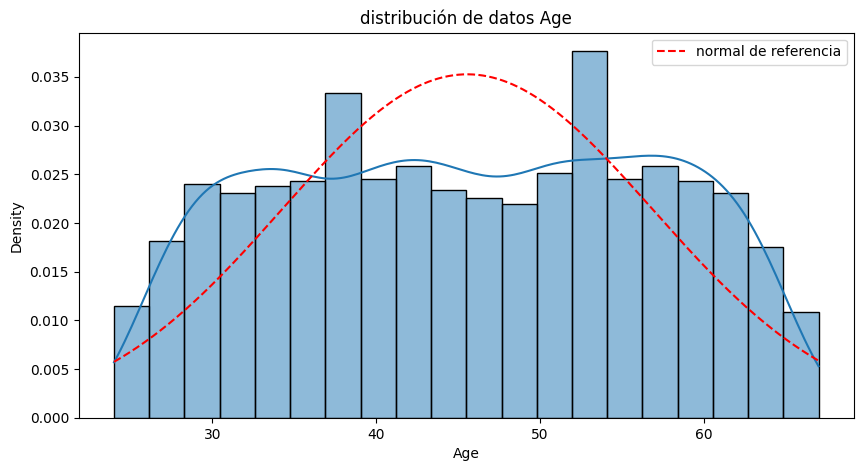

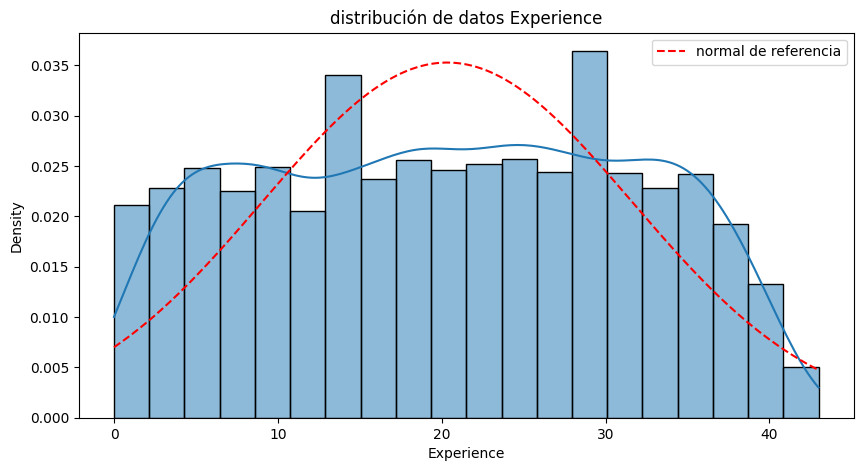

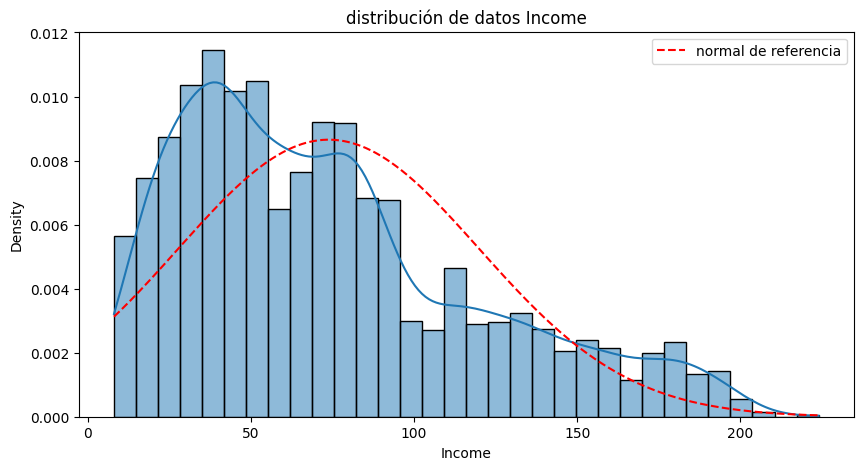

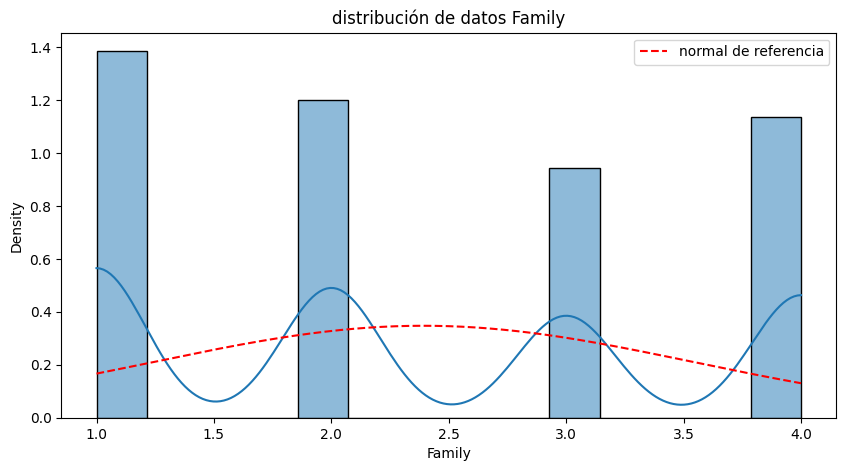

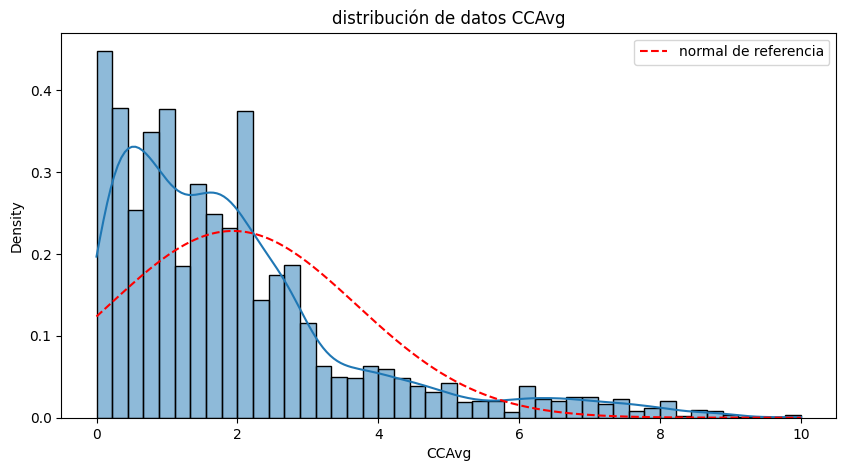

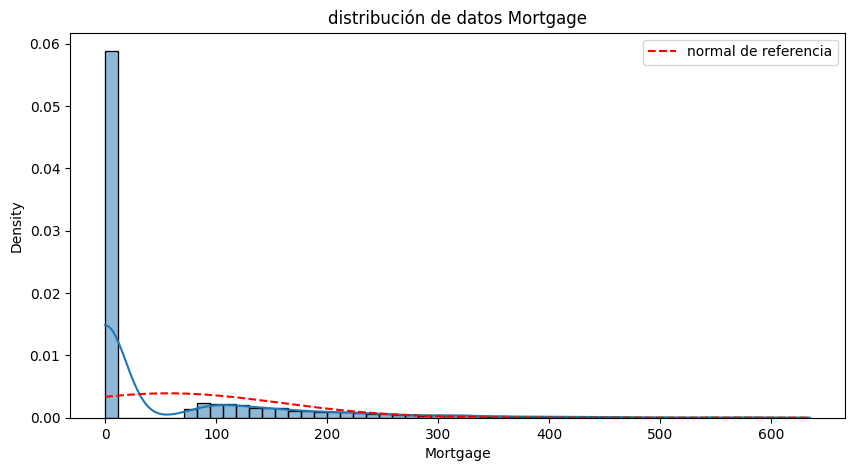

In [274]:
for columna in num_cols:
    plt.figure(figsize=(10, 5))

    # Histograma + curva KDE
    sns.histplot(data=loan_df, x=columna, kde=True, stat='density')

    # Curva normal de referencia
    x_vals = np.linspace(loan_df[columna].min(), loan_df[columna].max(), 1000)
    normal_ref = norm.pdf(x_vals, loc=loan_df[columna].mean(), scale=loan_df[columna].std())
    plt.plot(x_vals, normal_ref, color='red', linestyle='--', label='normal de referencia')

    plt.title(f'distribución de datos {columna}')
    plt.legend()
    plt.show()

***Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado***

la columna AGE coincide con ambos valores de simetría y curtosis.
la distribuición de los datos se extiende de forma pareja sin inclinarse hacia ningun extremo.
la curva KDE se observa mas ancha y plana que la curva normal de referencia.
no observamos un pico  central pronunciado, por lo que concuerda con la descripción de Platicúrtica (achatada)

Para Income vemos que también coincide, vemos una cola cargada a la derecha lo que indica asimetría positiva.
en cuanto a la curtosis se ve el pico más pronunciado que en la variable anterior, coincidiendo con una curva aproximadamente mesocúrtica.

para Mortgage observamos un histograma que se aparta mucho de lo que consideramos normal, ya que se ve un pico muy alto en los valores "0" y una cola muy larga hacia los montos mayores.
vemos la curtosis elevada o leptocúrtica

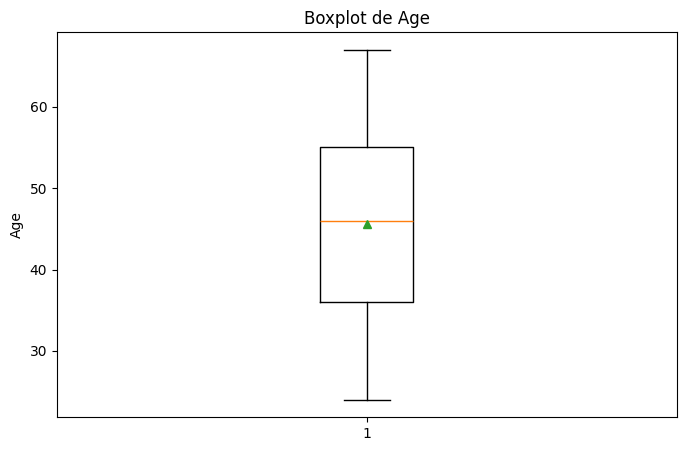

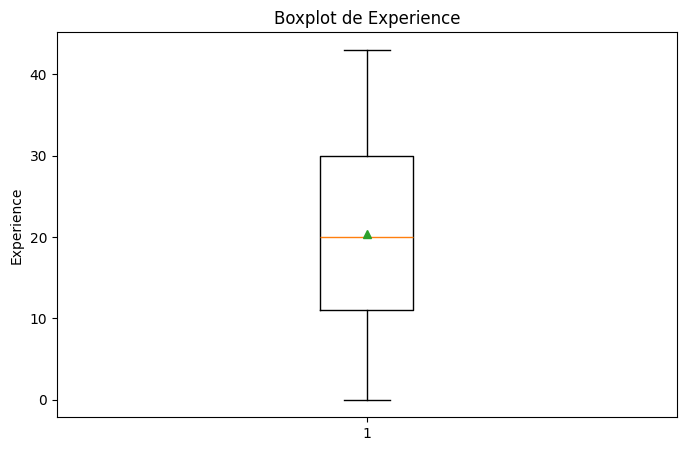

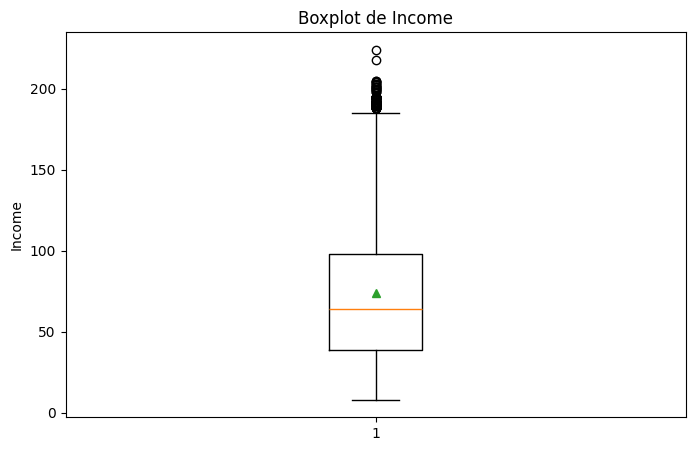

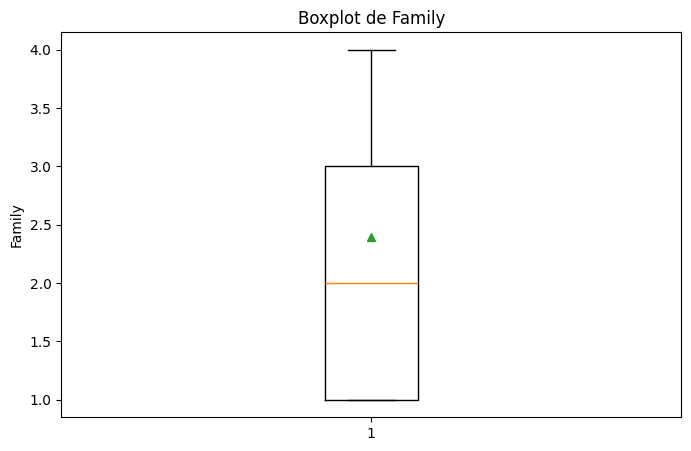

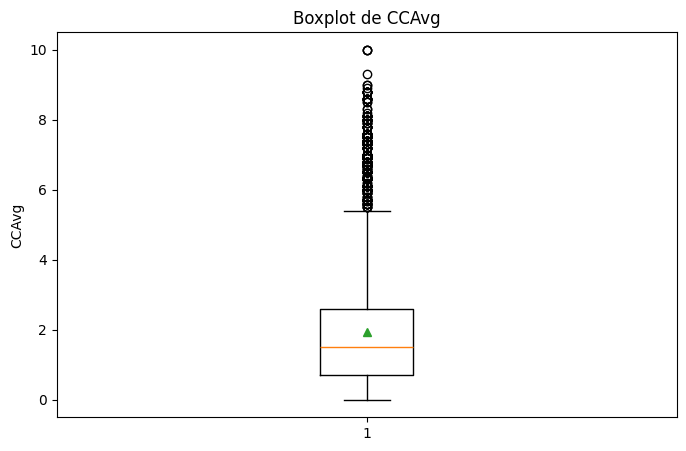

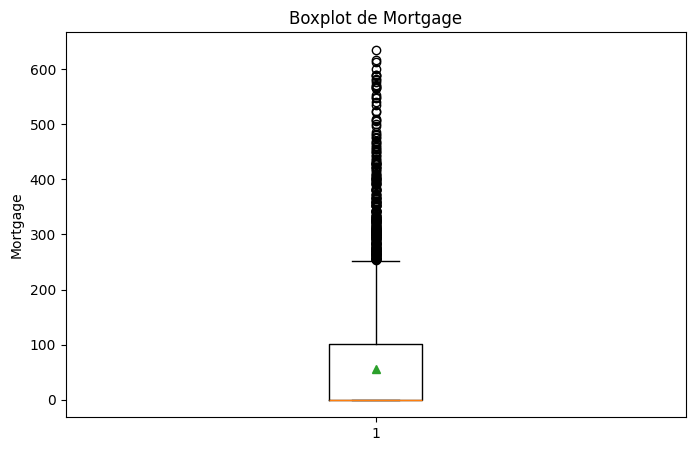

In [275]:
#Para cada variable, crea un gráfico de boxplot individual que incluya la media.
for col in num_cols:
    plt.figure(figsize=(8, 5))
    plt.boxplot(loan_df[col], showmeans=True)
    plt.title(f'Boxplot de {col}')
    plt.ylabel(col)
    plt.show()

***Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?***

en la variable AGE, vemos que no hay un sesgo, el triangulo verde de la media prácticamente coincide con la mediana, también vemos que ninguna cola predomina.

para income el triangulo de la media se encuentra por encima de la mediana, esto indicaría un sesgo positivo.en cuanto a los datos, significa que el promedio está elevado porque hay  personas que tienen un salario alto.

en mortgage se ve más marcada la separación, la media recae en el grupo de personas que no tienen una hipoteca. vemos que la media es positiva por lo que es un sesgo positivo.

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [276]:
#Obtén las estadísticas descriptivas de las variables categóricas
loan_df[cat_cols].describe().T

,count,unique,top,freq
ZIP Code,4942,468,94720,163
Education,4942,3,1,2079
Personal Loan,4942,2,0,4463
Securities Account,4942,2,0,4427
CD Account,4942,2,0,4641
Online,4942,2,1,2952
CreditCard,4942,2,0,3489


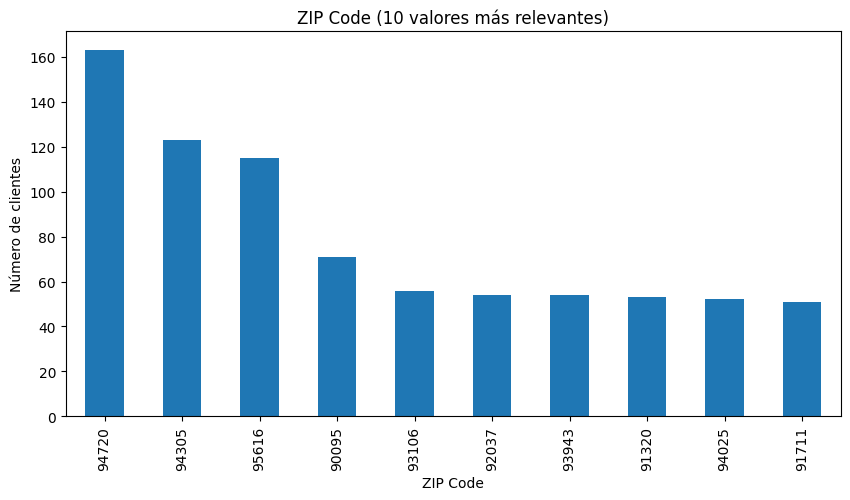

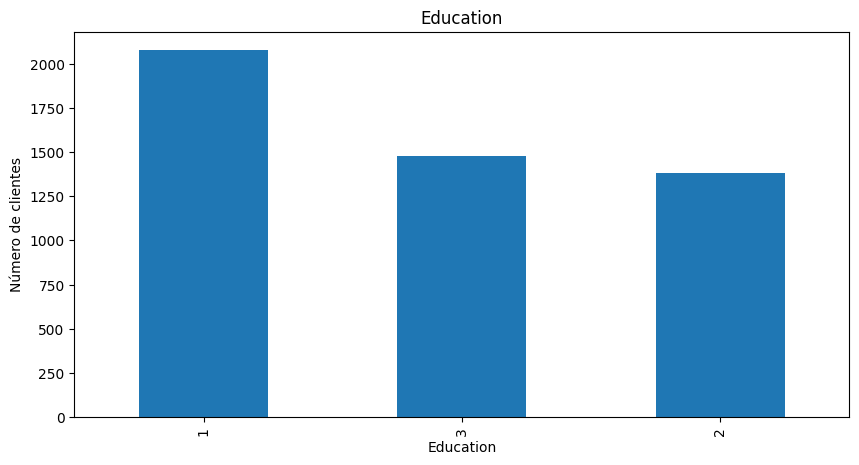

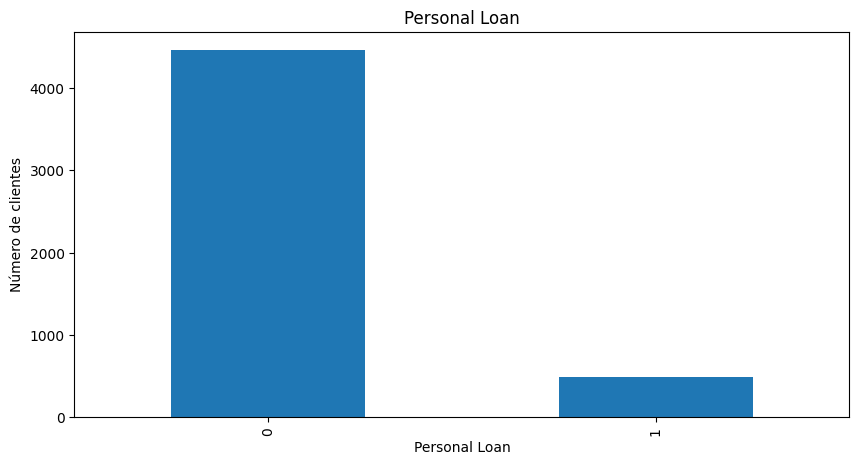

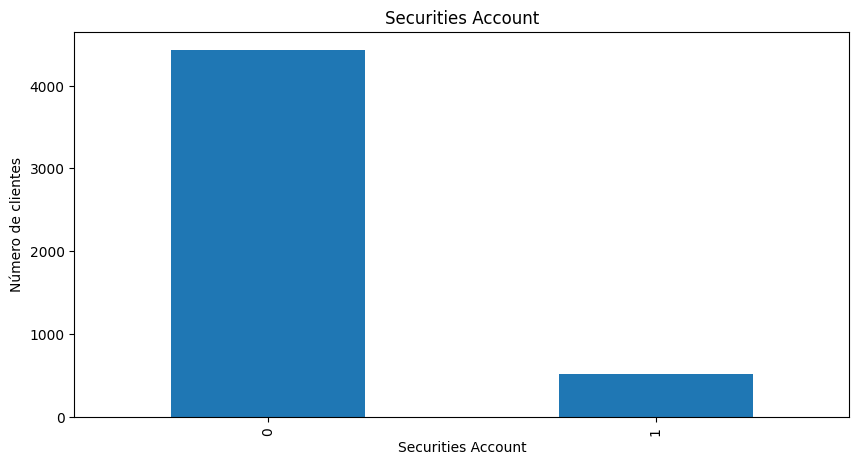

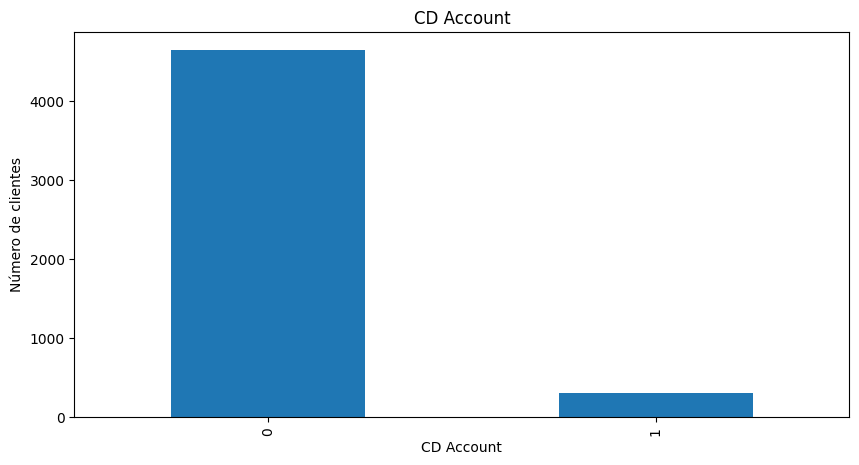

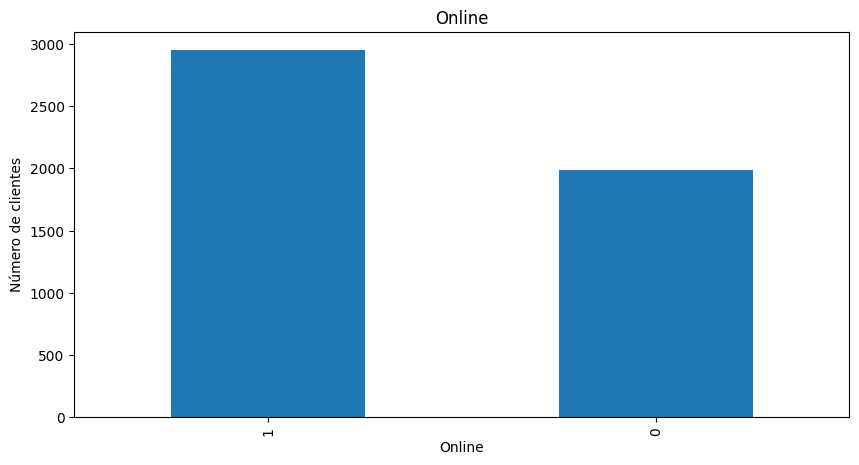

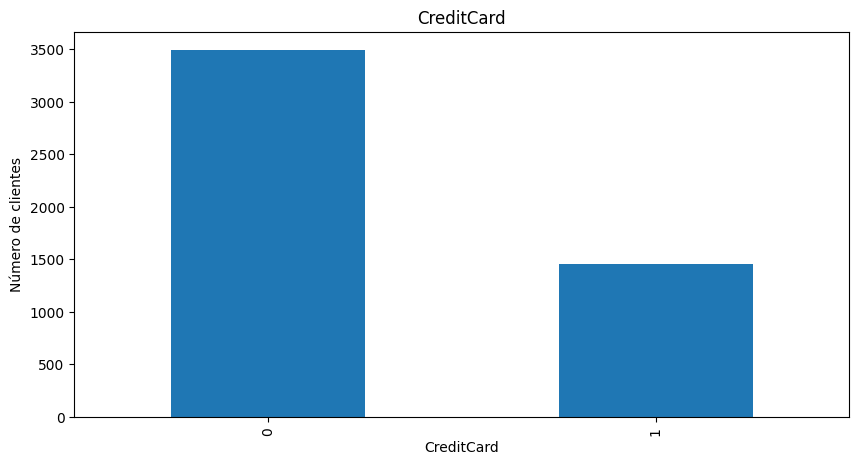

In [277]:
#Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.
for columna in cat_cols:
    frecuencias = loan_df[columna].value_counts()

    if len(frecuencias) > 10:
        frecuencias = frecuencias.nlargest(10)
        titulo = f'{columna} (10 valores más relevantes)'
    else:
        titulo = columna

    frecuencias.plot(kind='bar', figsize=(10, 5), title=titulo)
    plt.ylabel('Número de clientes')
    plt.xlabel(columna)
    plt.show()

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

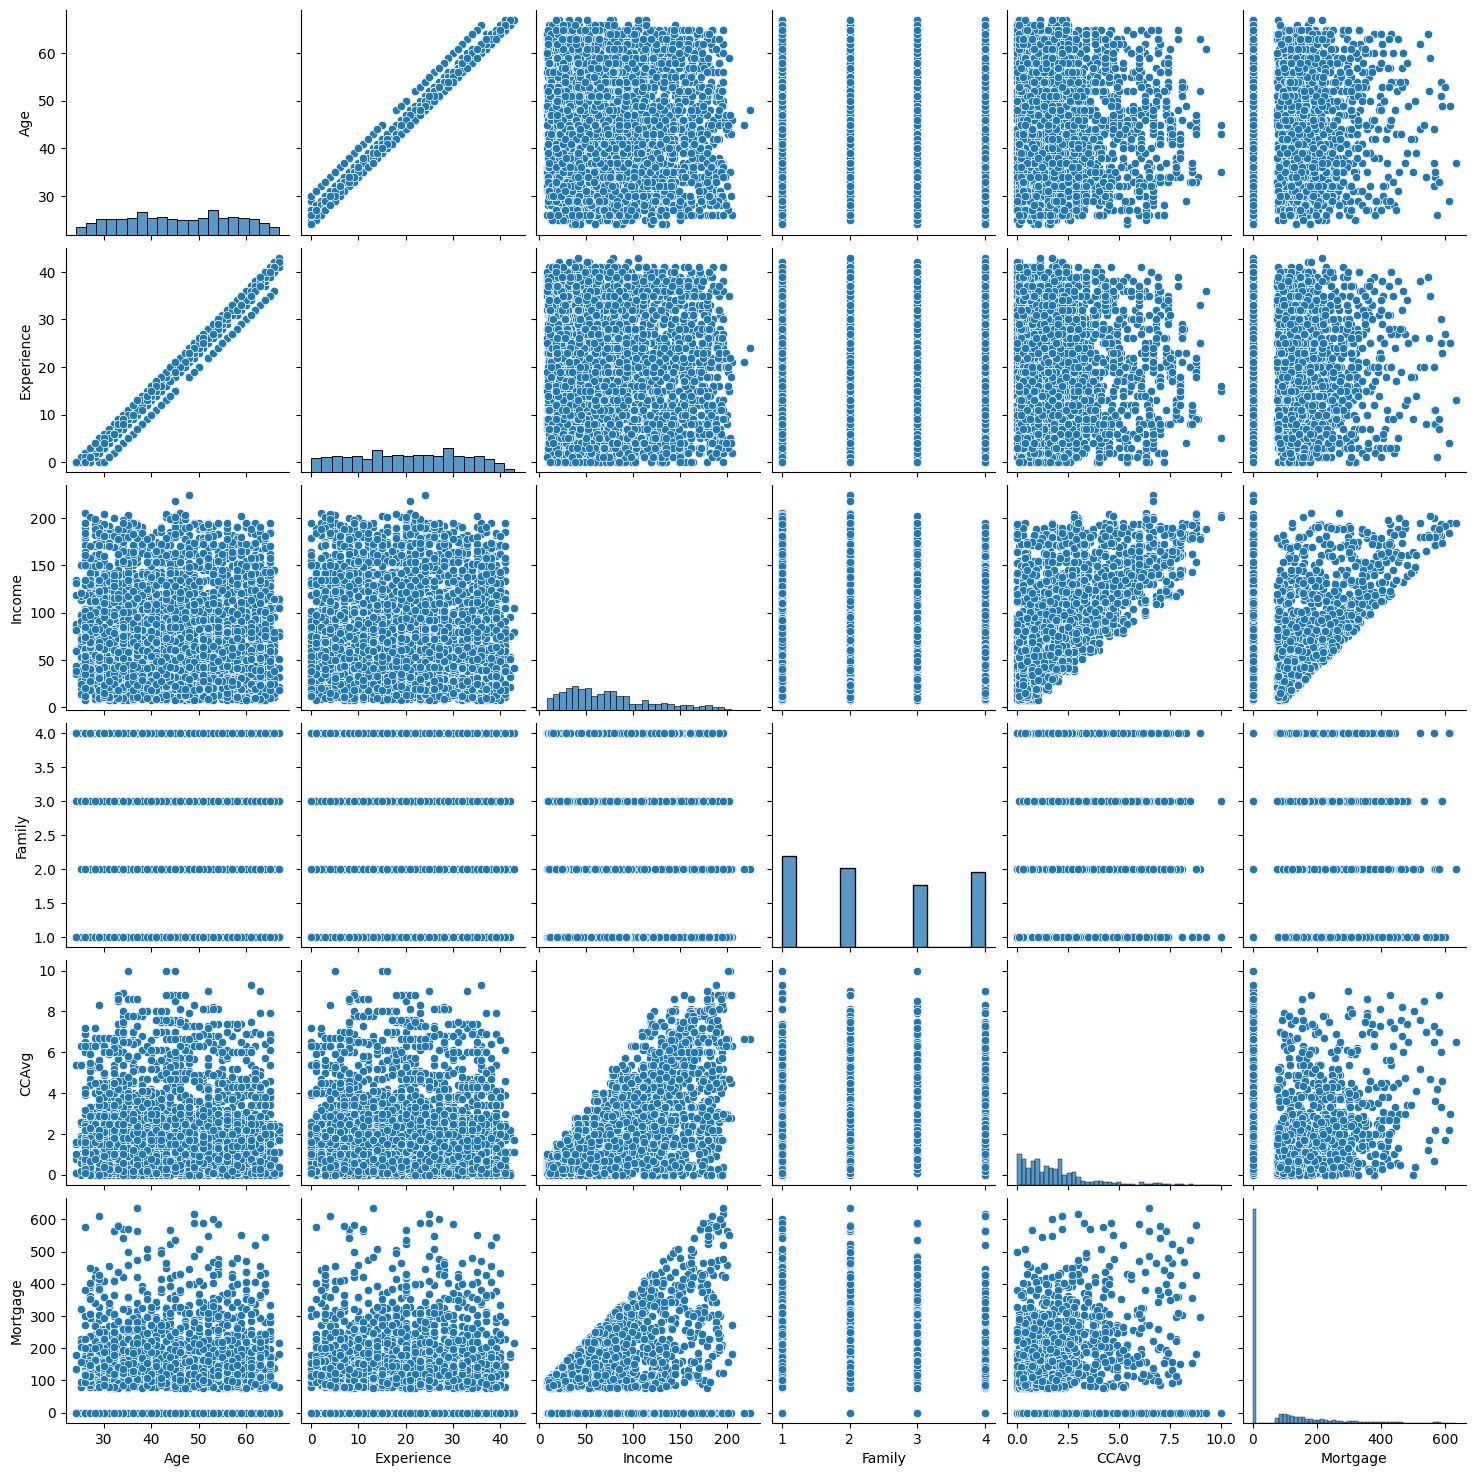

In [278]:
#Obtén la matriz de gráficos de dispersión (scatter matrix) de todas las variables numéricas.
sns.pairplot(loan_df[num_cols])
plt.show()

***Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.***
las vriables Incomer y CCAVG (ingreso anual contra gasto promedio mensual con tarjeta de crédito)

en el diagrama de dispersión se observa que entre más es el ingreso de una persona aumenta también el gasto promedio mensual con tarjeta de crédito.

a diferencia de las demás, vemos que el ingreso de las personas limita el gasto con tarjeta.

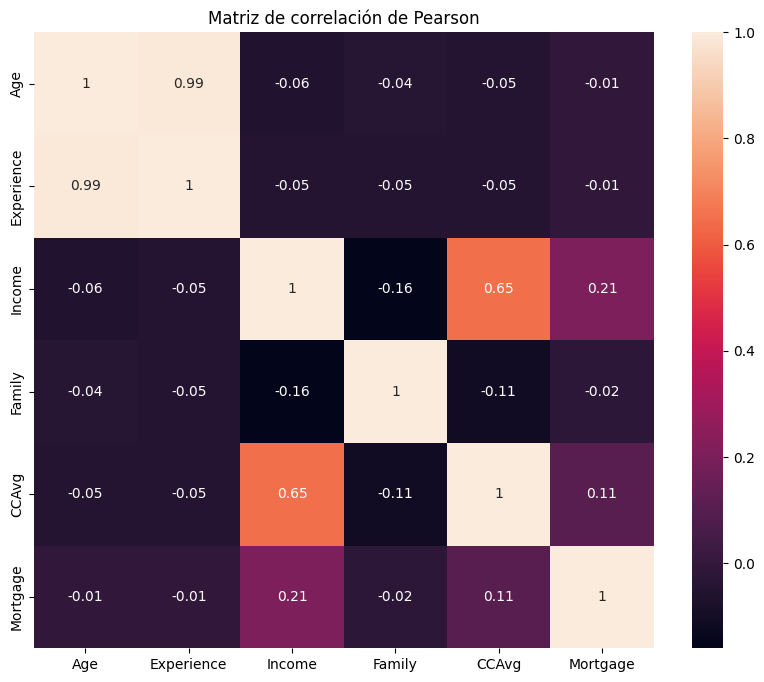

In [279]:
#Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de
# correlación de Pearson. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?
correlation = loan_df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(round(correlation, 2), annot=True)
plt.title('Matriz de correlación de Pearson')
plt.show()

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


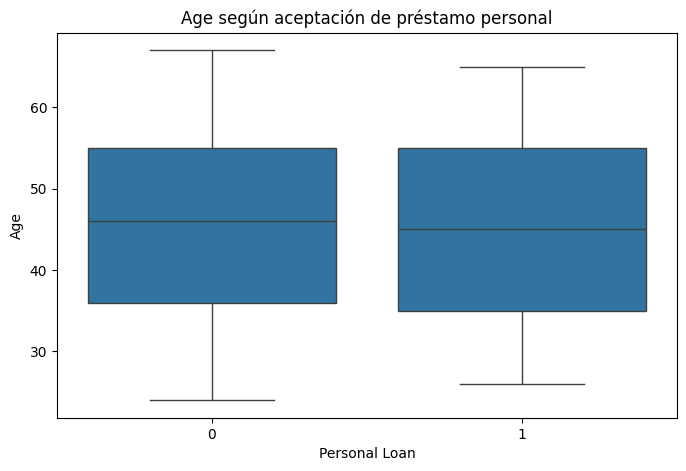

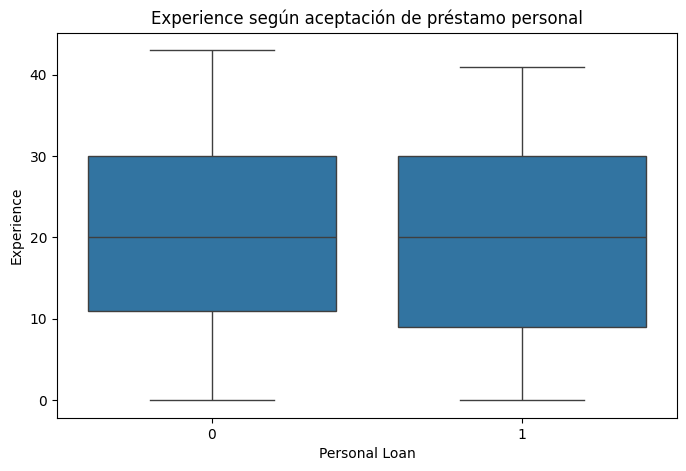

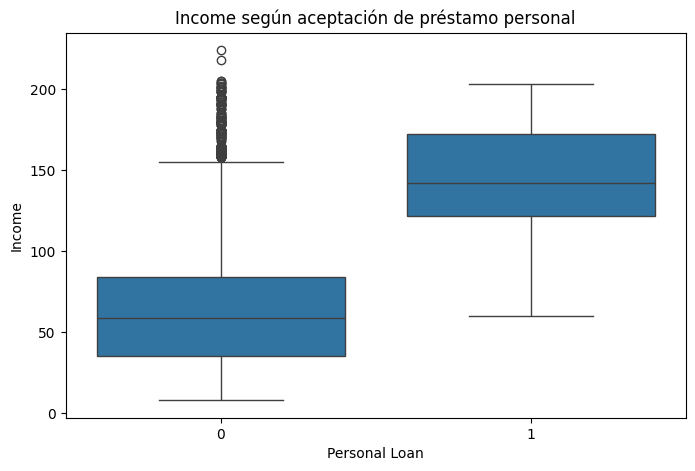

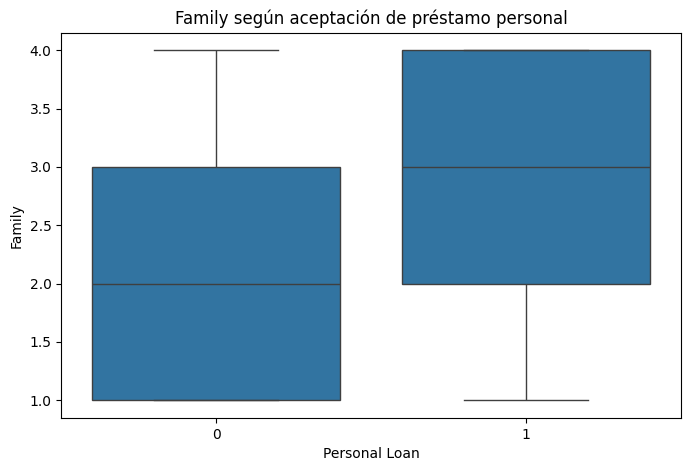

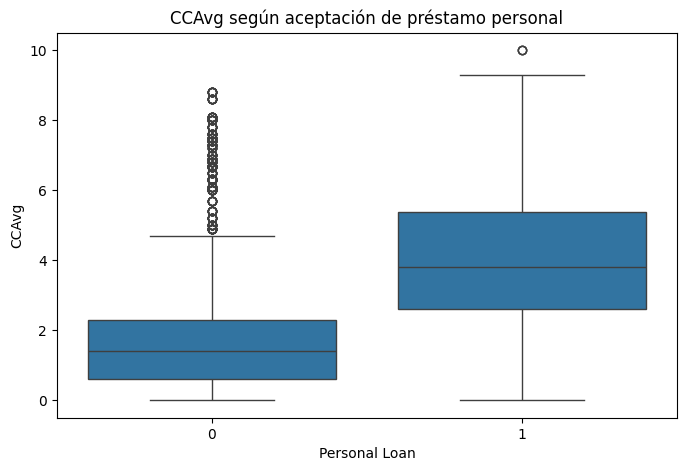

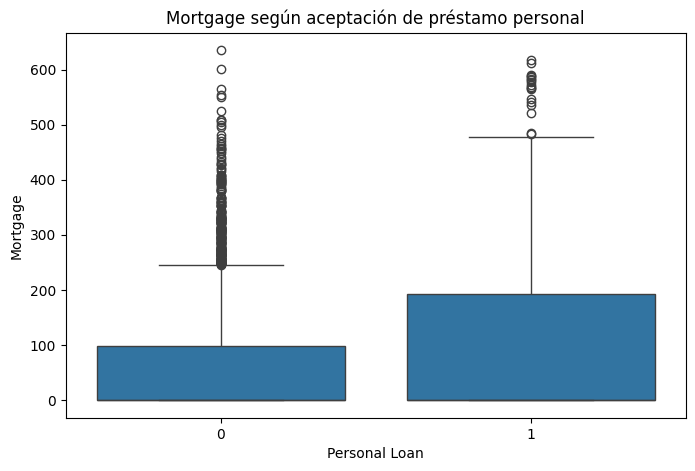

In [280]:
#Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de Personal Loan.
for col in num_cols:
    plt.figure(figsize=(8, 5))
    sns.boxplot(x='Personal Loan', y=col, data=loan_df)
    plt.title(f'{col} según aceptación de préstamo personal')
    plt.show()

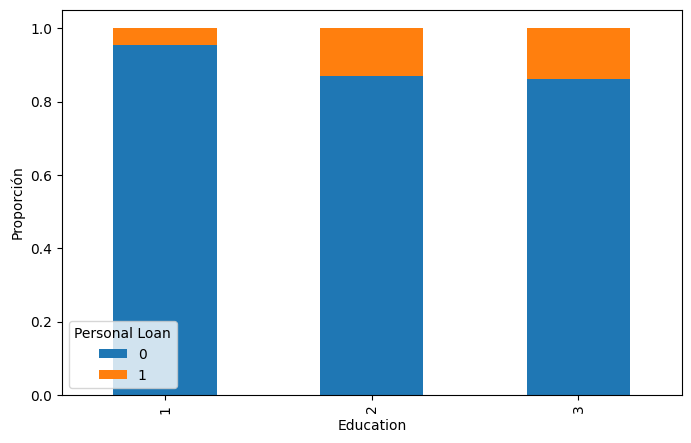

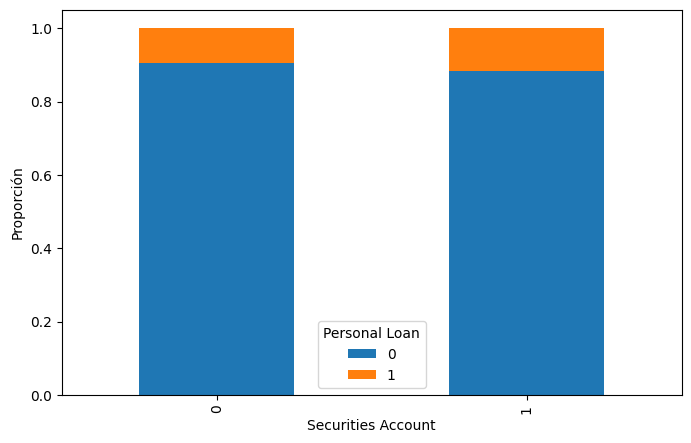

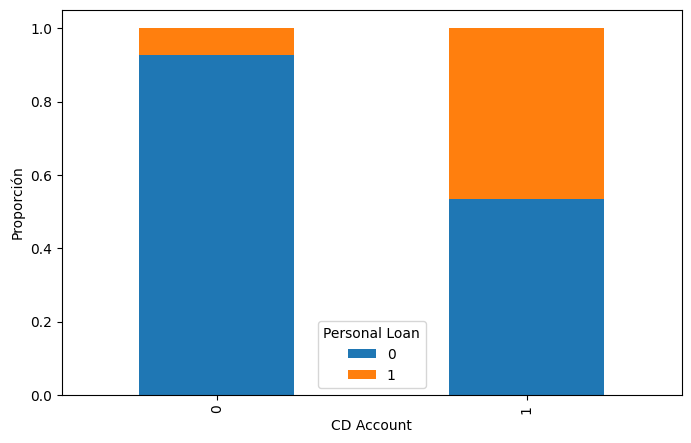

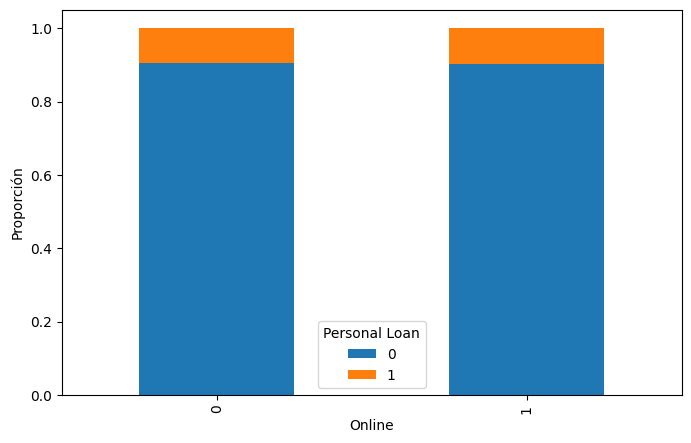

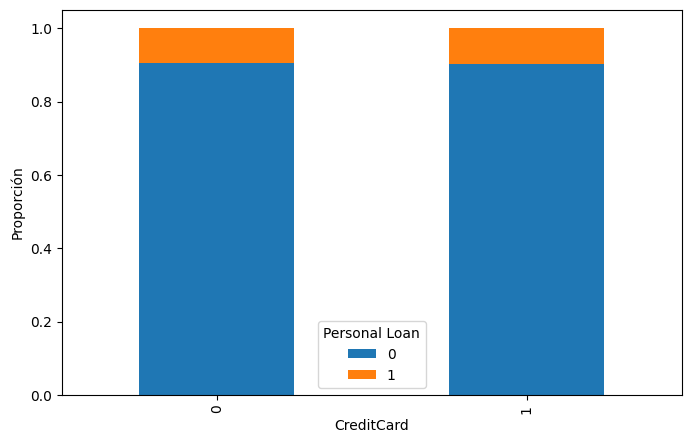

In [281]:
#Variables categóricas (sin considerar ZIP Code): Genera gráficos de barras apiladas que muestren la distribución
#relativa de Personal Loan dentro de cada categoría de la variable.
categor = [c for c in cat_cols if c not in ['ZIP Code', 'Personal Loan']]

for col in categor:
    tabla = pd.crosstab(loan_df[col], loan_df['Personal Loan'], normalize='index')
    tabla.plot(kind='bar', stacked=True, figsize=(8, 5))
    plt.ylabel('Proporción')
    plt.legend(title='Personal Loan')
    plt.show()

***Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados***

en el grupo de variables categóricas, en la gráfica de CCAVG se ve un patron en aquellas personas que tienen una cuenta de certificados de depósitos, estas tienden a aceptar un préstamo, quizás debido a que sus ahorros de dicha cuenta se encuentran a plazo fijo, por lo que no pueden disponer de ellos en el momento en que lo deseen porque podrían ser penalizados, por lo que son más propensos a acpetar un préstamo personal.

en la variable Income se ve un patron marcado, la aceptación del préstamo está condicionado por la capacidad económica de la persona



Anthropic. (2026). Claude (Opus 5) [Modelo de lenguaje grande], utilizado para tutoría, depuración de código, generación de ejemplos relacionados al tema. https://claude.ai/

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---